In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

# Toy problem

In [2]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
F = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
noisy_signal = F.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

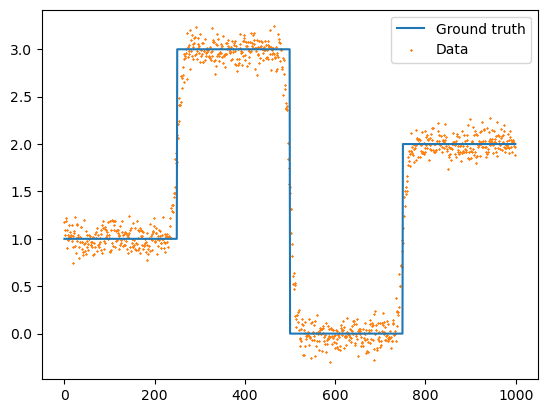

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization matrix

In [4]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

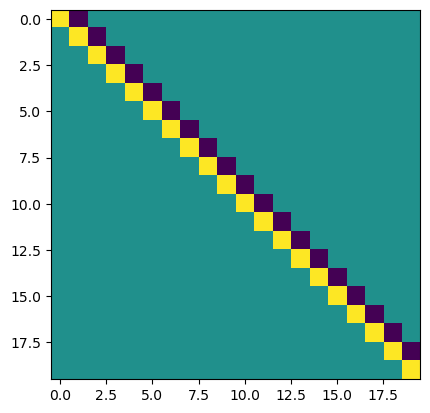

In [5]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Solve problem with GKS-IAS

First, we will solve the problem with GKS-IAS. Then, we will use the selected $\vartheta$ parameter when we solve the problem with IAS / P-IAS (priorconditioned IAS). When we compare GKS-IAS with IAS/P-IAS, keep in mind that the later take $\vartheta$ as an input.

In [6]:
from gksias import GKSIAS

In [120]:
# Define hyperprior paramaeters
hyperpr_r = -1.0
hyperpr_beta = 1.0

# Whiten the forward operator and observation by the noise covariance (don't actually need to do this when using gcv)
Atilde = (1.0/noise_stdev)*F
btilde = (1.0/noise_stdev)*noisy_signal

# Solve problem with GKSIAS
gks_sol, gks_data = GKSIAS(Atilde, btilde, L, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
                           projection_dim=3, n_iter=200, regparam="gcv", x_true=ground_truth)

running MMGKS...: 100%|██████████| 200/200 [00:43<00:00,  4.60it/s]


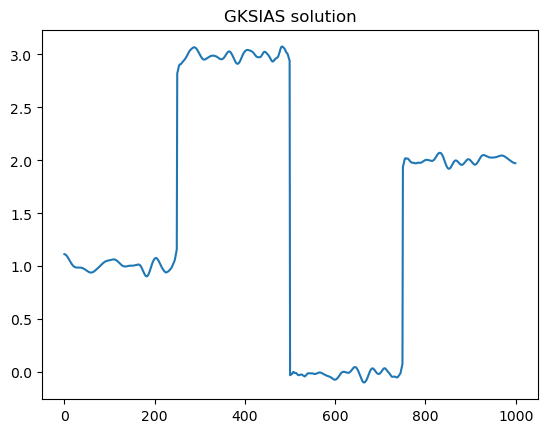

In [121]:
plt.plot( gks_sol )
plt.title("GKSIAS solution")
plt.show()

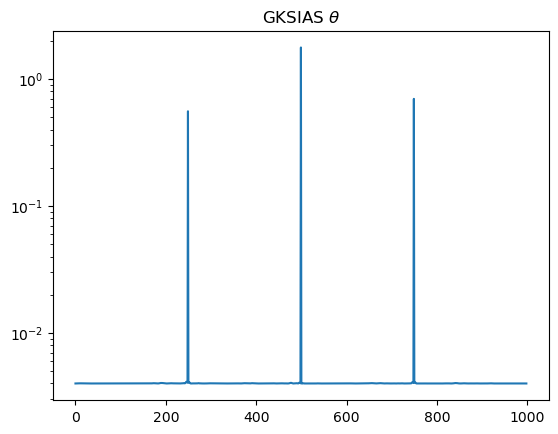

In [122]:
plt.plot(gks_data["theta"])
plt.title("GKSIAS $\\theta$")
plt.yscale("log")
plt.show()

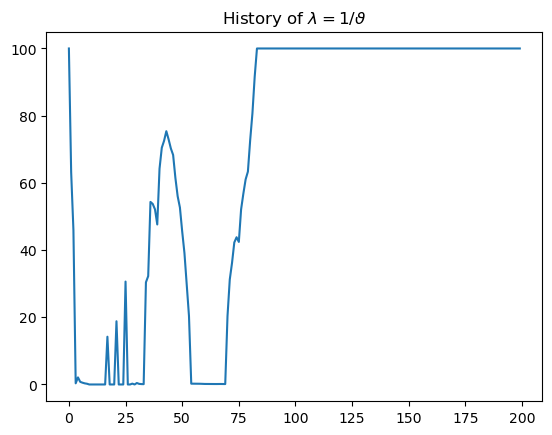

In [123]:
plt.plot(gks_data["regParam_history"])
plt.title("History of $\\lambda = 1/\\vartheta$")
plt.show()

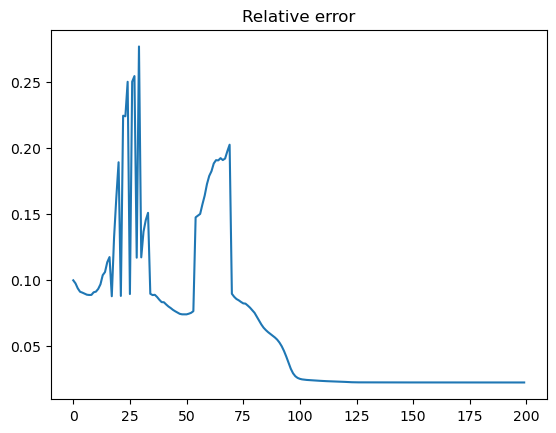

In [124]:
plt.plot(gks_data["relError"])
plt.title("Relative error")
plt.show()

### Set up IAS and IAS with priorconditioning

In [12]:
from ias import IASSolver

In [146]:
# Prior parameters
hyperparams = {
    "prior": {
        "r": hyperpr_r,
        "beta": hyperpr_beta,
        "vartheta": gks_data["vartheta_history"][-1], # use vartheta from GKS
    },
}

# Set up priorconditioning pseudoinverse factory (shortcut here since linearly indpendent rows, less of a cheating way below)
_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda theta: _Lpinv @ jlinops.DiagonalOperator(np.sqrt(theta))

# def Rpinv_factory(theta):
#     Rtilde = jlinops.MatrixLinearOperator(sps.diags(1.0/np.sqrt(theta)) @ Rmat)
#     return jlinops.BandedCholeskyPinvOperator(Rtilde, delta=1e-8)

pdata = {
    "W": jlinops.MatrixLinearOperator(Wmat),
    "Rpinv_factory": Lpinv_factory,
}

# Create solver
ias_solver = IASSolver(F, L, noisy_signal, hyperparams, noise_var=noise_var, pdata={})
pias_solver = IASSolver(F, L, noisy_signal, hyperparams, noise_var=noise_var, pdata=pdata)

In [147]:
ias_data = ias_solver.solve(max_iters=200, eps=1e-8, x_update_solver_params={"tol":1e-7}, x_true=ground_truth)
pias_data = pias_solver.solve(max_iters=200, eps=1e-8, x_update_solver_params={"tol":1e-6}, x_true=ground_truth, priorconditioning=True)

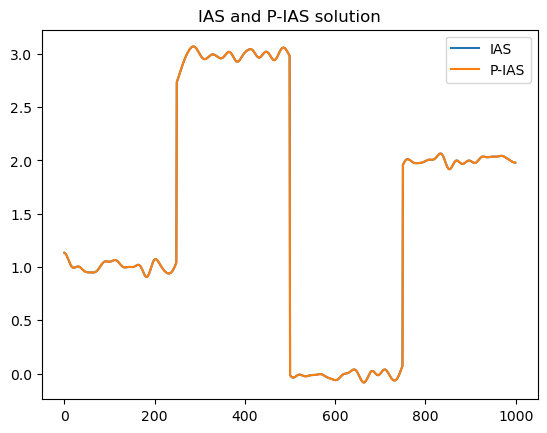

In [148]:
plt.plot(ias_data["x"], label="IAS")
plt.plot(pias_data["x"], label="P-IAS")
plt.title("IAS and P-IAS solution")
plt.legend()
plt.show()

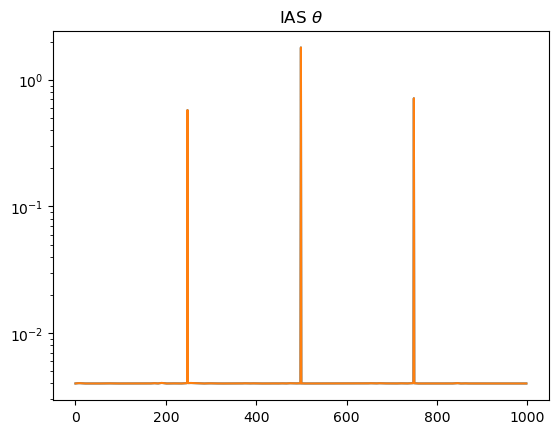

In [149]:
plt.plot(ias_data["theta"])
plt.plot(pias_data["theta"])
plt.title("IAS $\\theta$")
plt.yscale("log")
plt.show()

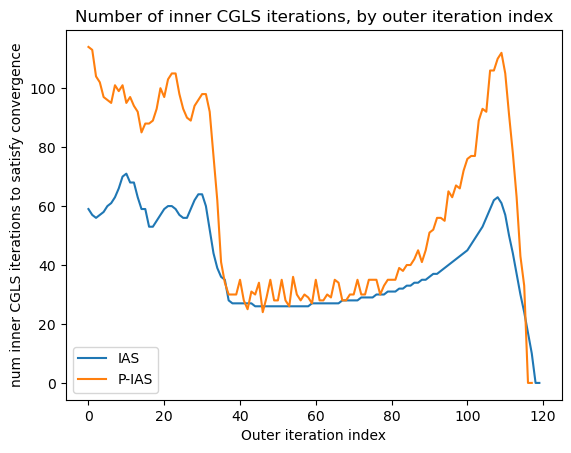

In [150]:
plt.plot(ias_data["n_cg_its_per_iteration"], label="IAS")
plt.plot(pias_data["n_cg_its_per_iteration"], label="P-IAS")
plt.title("Number of inner CGLS iterations, by outer iteration index")
plt.xlabel("Outer iteration index")
plt.ylabel("num inner CGLS iterations to satisfy convergence")
plt.legend()
plt.show()

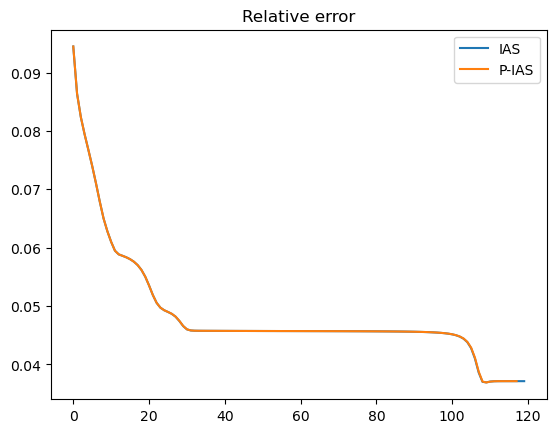

In [152]:
plt.plot(ias_data["rel_errs"], label="IAS")
plt.plot(pias_data["rel_errs"], label="P-IAS")
plt.title("Relative error")
plt.legend()
plt.show()

# Comparison 

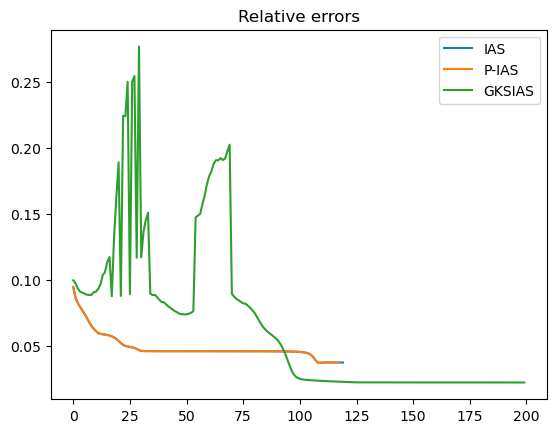

In [155]:
plt.plot(ias_data["rel_errs"], label="IAS")
plt.plot(pias_data["rel_errs"], label="P-IAS")
plt.plot(gks_data["relError"], label="GKSIAS")
plt.legend()
plt.title("Relative errors")
plt.show()

In [ ]:
plt.plot(ias_data["rel_errs"], label="IAS")
plt.plot(pias_data["rel_errs"], label="P-IAS")
plt.plot(gks_data["relError"], label="GKSIAS")
plt.legend()
plt.title("Title")
plt.show()

# Stronger regularization

In the previous example, there is apparently not a great benefit to using priorconditioning. Here, we repeat the same example but dial up the strength of regularization (smaller $\vartheta$ than the one chosen by GCV) to show how it only really begins to benefit from there is true sparsity in the solution.

In [ ]:
from ias import IASSolver

In [137]:
# Prior parameters
hyperparams = {
    "prior": {
        "r": hyperpr_r,
        "beta": hyperpr_beta,
        "vartheta": 1e-4, # use vartheta from GKS
    },
}

# Set up priorconditioning pseudoinverse factory (shortcut here since linearly indpendent rows, less of a cheating way below)
_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda theta: _Lpinv @ jlinops.DiagonalOperator(np.sqrt(theta))

# def Rpinv_factory(theta):
#     Rtilde = jlinops.MatrixLinearOperator(sps.diags(1.0/np.sqrt(theta)) @ Rmat)
#     return jlinops.BandedCholeskyPinvOperator(Rtilde, delta=1e-8)

pdata = {
    "W": jlinops.MatrixLinearOperator(Wmat),
    "Rpinv_factory": Lpinv_factory,
}

# Create solver
ias_solver = IASSolver(F, L, noisy_signal, hyperparams, noise_var=noise_var, pdata={})
pias_solver = IASSolver(F, L, noisy_signal, hyperparams, noise_var=noise_var, pdata=pdata)

In [138]:
ias_data = ias_solver.solve(max_iters=200, eps=1e-8, x_update_solver_params={"tol":1e-7}, x_true=ground_truth)
pias_data = pias_solver.solve(max_iters=200, eps=1e-8, x_update_solver_params={"tol":1e-6}, x_true=ground_truth, priorconditioning=True)

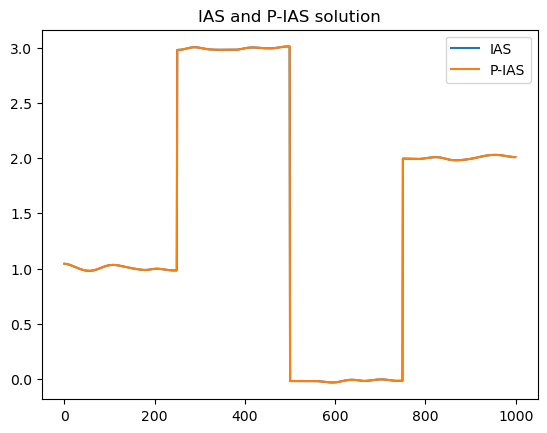

In [140]:
plt.plot(ias_data["x"], label="IAS")
plt.plot(pias_data["x"], label="P-IAS")
plt.title("IAS and P-IAS solution")
plt.legend()
plt.show()

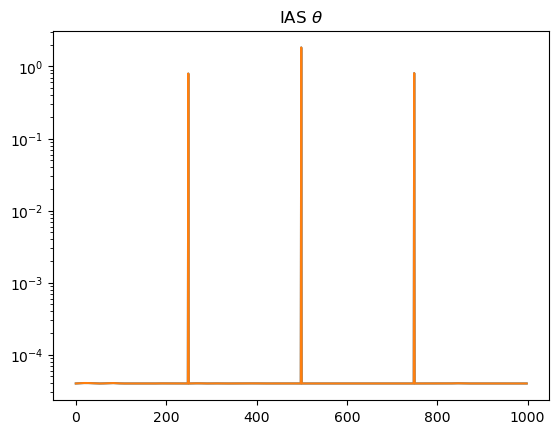

In [141]:
plt.plot(ias_data["theta"])
plt.plot(pias_data["theta"])
plt.title("IAS $\\theta$")
plt.yscale("log")
plt.show()

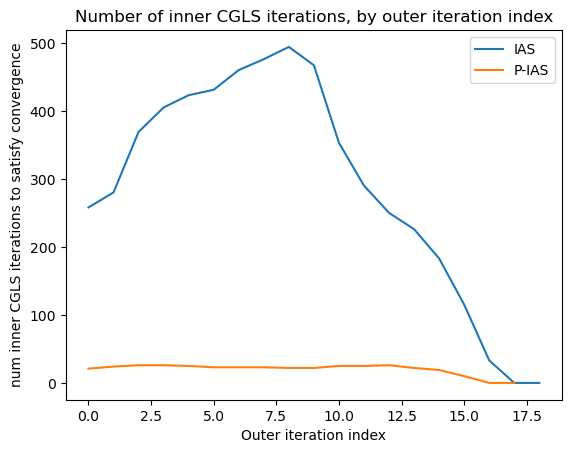

In [142]:
plt.plot(ias_data["n_cg_its_per_iteration"], label="IAS")
plt.plot(pias_data["n_cg_its_per_iteration"], label="P-IAS")
plt.title("Number of inner CGLS iterations, by outer iteration index")
plt.xlabel("Outer iteration index")
plt.ylabel("num inner CGLS iterations to satisfy convergence")
plt.legend()
plt.show()

My conclusion is that as long as GCV is selecting such a large regularization parameter, priorconditioning will not be useful.